# pL2 Autofluorescence

1) CD1 - Conrad's first run of the experimental protocol (2025-05-13)
2) CD2 - Conrad's second run of the experimental protocol (2025-05-28)
3) AL1 - my first run of the experimental protocol (2025-10-21)

# Setup

In [ ]:
## SHARED CONFIG ##

import importlib

import analyse_pr_config

# Reload configs on each run.
importlib.reload(analyse_pr_config)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from analyse_pr_config import (
    AUTOFLUORESCENCE_ORDER,
    CONDITION_COLORS,
    FIGURE_DPI,
    LABEL_FONTSIZE,
    LEGEND_FONTSIZE,
    PL2_FIT_CUTOFF,
    REPLICATES,
    SAMPLING_METHOD,
    TAGS,
    TICK_FONTSIZE,
    biomass_and_floor,
    blank_series,
    load_plate_series,
    smooth,
)
from matplotlib.colors import LinearSegmentedColormap

from bioutils import transform

## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI
plt.rcParams["savefig.dpi"] = FIGURE_DPI

FIGSIZE_CALIBRATION = (6.3, 2.5)
FIGSIZE_F_TIME = (6.3, 2.2)
INDEX_CMAP = LinearSegmentedColormap.from_list(
    "dusk", ["#221150", "#5f187f", "#982d80", "#d3436e", "#f8765c", "#febb81"])


## OUTPUT ##
OUT_DIR = Path("out")


## CIRCUIT ##
# To show in the notebook
CIRCUIT = 75



In [2]:
# Load data
od_raw, fl_raw, t_minutes = load_plate_series()

for tag in TAGS:
    print(f"{tag}: plate shape={od_raw[tag].shape}, runtime={t_minutes[tag][-1]:.0f} min")


Rep1: plate shape=(16, 24, 41), runtime=480 min
Rep2: plate shape=(16, 24, 41), runtime=480 min
Rep3: plate shape=(16, 24, 41), runtime=480 min


## Blank Subtraction

In [ ]:
## DETECTION THRESHOLD ##
t_minutes_shared = t_minutes[TAGS[0]]

POOLED_BLANK, DETECTION_THRESHOLD, POOLED_BLANK_FL = blank_series(od_raw, fl_raw)


In [ ]:
# Subtract the plate's pooled blank from OD and from F.

circuit_biomass, circuit_fl_no_bg = {}, {}
pl2_biomass, pl2_fl_no_bg = {}, {}

for rep in REPLICATES:
    tag = rep["tag"]
    for wells, biomass_dict, fl_no_bg_dict in [
        (rep["wells"]["circuits"][CIRCUIT], circuit_biomass, circuit_fl_no_bg),
        (rep["wells"]["pL2"], pl2_biomass, pl2_fl_no_bg),
    ]:
        rows, cols = zip(*wells)
        # smoothed, pooled-blank-corrected, and the floor tested on that same series
        biomass_dict[tag], _ = biomass_and_floor(
            od_raw[tag][list(rows), list(cols), :], POOLED_BLANK[tag],
            DETECTION_THRESHOLD[tag])
        # F smoothed before the blank comes off, as OD is
        fl_no_bg_dict[tag] = (smooth(fl_raw[tag][list(rows), list(cols), :])
                              - POOLED_BLANK_FL[tag])


## Sampled Point


In [ ]:
# The sampled timepoint and the OD at it are taken from analyse_pr_biomass.ipynb

growth_summary = pd.read_csv(OUT_DIR / "analyse_pr_biomass.csv",
                             keep_default_na=False, na_values=[""])


def growth_row(group, rep, condition):
    """The one biomass-summary row for a (group, replicate, condition)."""
    match = growth_summary[(growth_summary["Group"] == group)
                           & (growth_summary["Rep"] == rep["label"])
                           & (growth_summary["Condition"] == rep["cond_labels"][condition])]
    if len(match) != 1:
        raise ValueError(f"{group}/{rep['label']}/{rep['cond_labels'][condition]}: "
                         f"matched {len(match)} rows, expected 1")
    return match.iloc[0]


def read_sampled_od(group, rep, condition):
    """Blank-corrected biomass at the sampled point."""
    return float(growth_row(group, rep, condition)[f"biomass_at_sampled_{SAMPLING_METHOD}"])


# pL2 excluded: it defines the curve
corrected_groups = growth_summary[growth_summary["Group"] != "pL2"]

# Every circuit's sampled OD, per plate
circuit_sampled_ods = {}
for rep in REPLICATES:
    plate = corrected_groups[(corrected_groups["Rep"] == rep["label"])
                             & corrected_groups["Group"].str.startswith("Circuit ")]
    circuit_sampled_ods[rep["tag"]] = (
        plate[f"biomass_at_sampled_{SAMPLING_METHOD}"].dropna().to_numpy())

print(f"sampled ODs for Circuit {CIRCUIT}, pRPU and pL2 read from "
      f"{OUT_DIR / 'analyse_pr_biomass.csv'}")


sampled timepoints and ODs for Circuit 75, pRPU and pL2 read from out/analyse_pr_biomass.csv


## Autofluorescence Correction

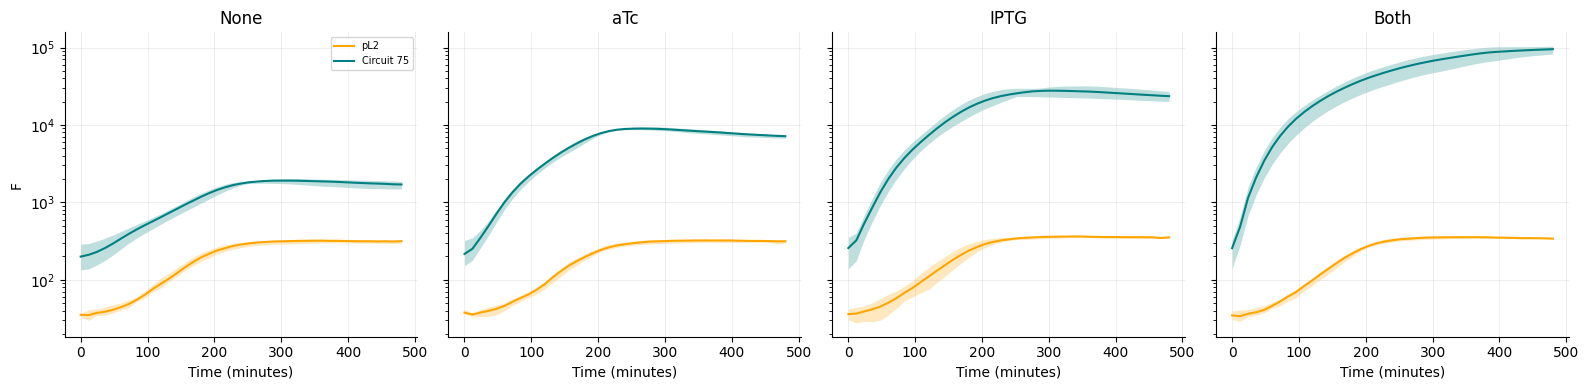

In [8]:
# Bulk F: pL2 vs circuit
series = (("pL2", pl2_fl_no_bg, "orange"),
          (f"Circuit {CIRCUIT}", circuit_fl_no_bg, "teal"))

t = np.mean([t_minutes[rep["tag"]] for rep in REPLICATES], axis=0)

fig, axes = plt.subplots(1, 4, figsize=FIGSIZE_F_TIME, sharex=True, sharey=True)

for well in range(4):
    ax = axes[well]

    for label, store, colour in series:
        across_replicates = np.stack([store[rep["tag"]][well] for rep in REPLICATES])
        ax.fill_between(t, across_replicates.min(axis=0), across_replicates.max(axis=0),
                        color=colour, alpha=0.25, linewidth=0)
        ax.plot(t, across_replicates.mean(axis=0), color=colour, lw=1.0, label=label)

    ax.set_title(REPLICATES[0]["cond_labels"][well], fontsize=LABEL_FONTSIZE)
    ax.set_xlabel("Time (minutes)", fontsize=LABEL_FONTSIZE)
    ax.grid(True, alpha=0.3, linewidth=0.5)
    ax.set_yscale("log")
    ax.tick_params(which="both", labelsize=TICK_FONTSIZE)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    if well == 0:
        ax.set_ylabel("F", fontsize=LABEL_FONTSIZE)
        ax.legend(fontsize=LEGEND_FONTSIZE, handlelength=1.2, borderpad=0.4,
                  labelspacing=0.3)

plt.tight_layout()
plt.show()


In [9]:
# Above-floor mask
pl2_above_floor = {tag: pl2_biomass[tag] >= DETECTION_THRESHOLD[tag] for tag in TAGS}

autof_per_cell = {tag: np.where(pl2_above_floor[tag],
                                pl2_fl_no_bg[tag] / pl2_biomass[tag], np.nan)
                  for tag in TAGS}


In [10]:
# Biomass at each group's own sampled timepoint

circuit_biomass_at_sampled = {
    rep["tag"]: [read_sampled_od(f"Circuit {CIRCUIT}", rep, w) for w in range(4)]
    for rep in REPLICATES}
pRPU_biomass_at_sampled = {
    rep["tag"]: [read_sampled_od("pRPU", rep, w) for w in range(4)]
    for rep in REPLICATES}
pl2_biomass_at_sampled = {
    rep["tag"]: [read_sampled_od("pL2", rep, w) for w in range(4)]
    for rep in REPLICATES}



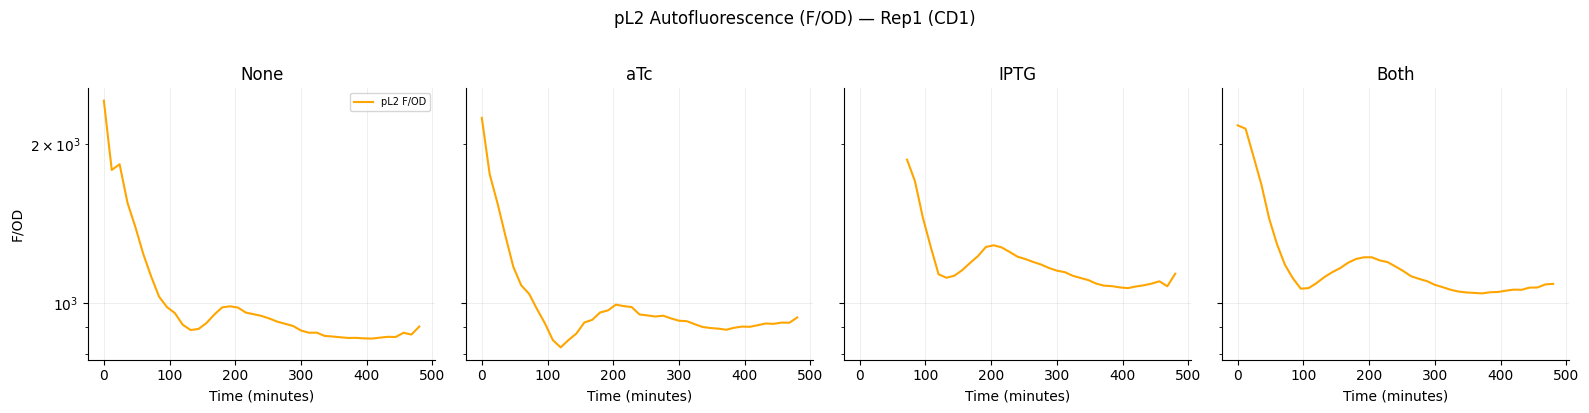

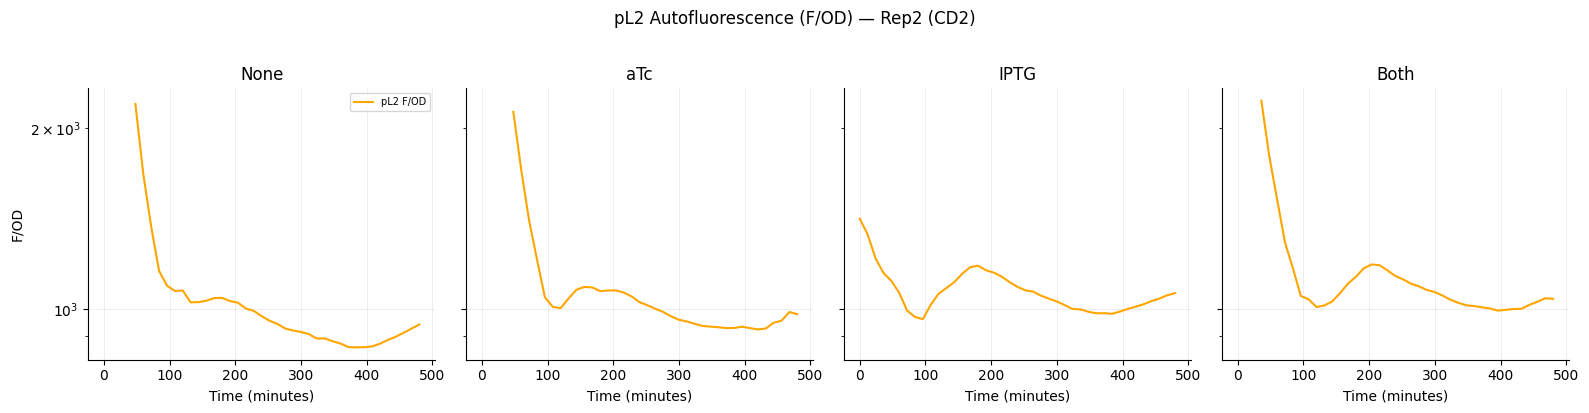

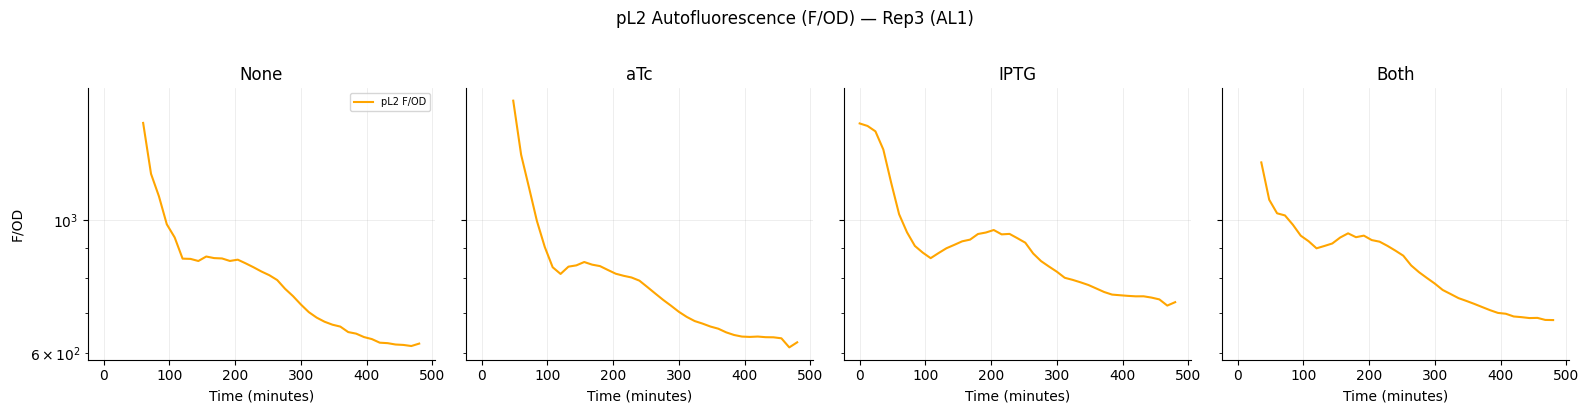

In [ ]:
# pL2 F/OD
# This should be stable in the exponential growth phase

for rep in REPLICATES:
    tag = rep["tag"]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)

    for well in range(4):
        ax = axes[well]

        # F/OD
        ax.plot(t_minutes[tag],
                autof_per_cell[tag][well],
                color="orange",
                lw=1.5,
                label="pL2 F/OD")

        ax.set_title(REPLICATES[0]["cond_labels"][well])
        ax.set_xlabel("Time (minutes)")
        ax.grid(True, alpha=0.3, linewidth=0.5)
        ax.set_yscale("log")
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        if well == 0:
            ax.set_ylabel("F/OD")
            ax.legend(fontsize=7)

    fig.suptitle(f"pL2 Autofluorescence (F/OD) — {tag} ({rep['label']})", y=1.02)
    plt.tight_layout()
    plt.show()


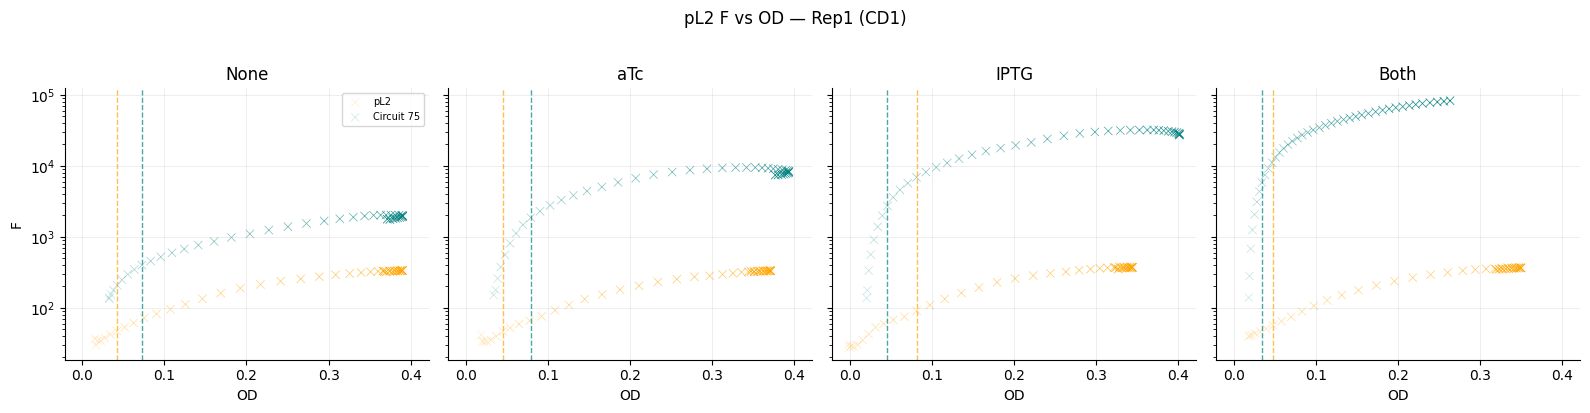

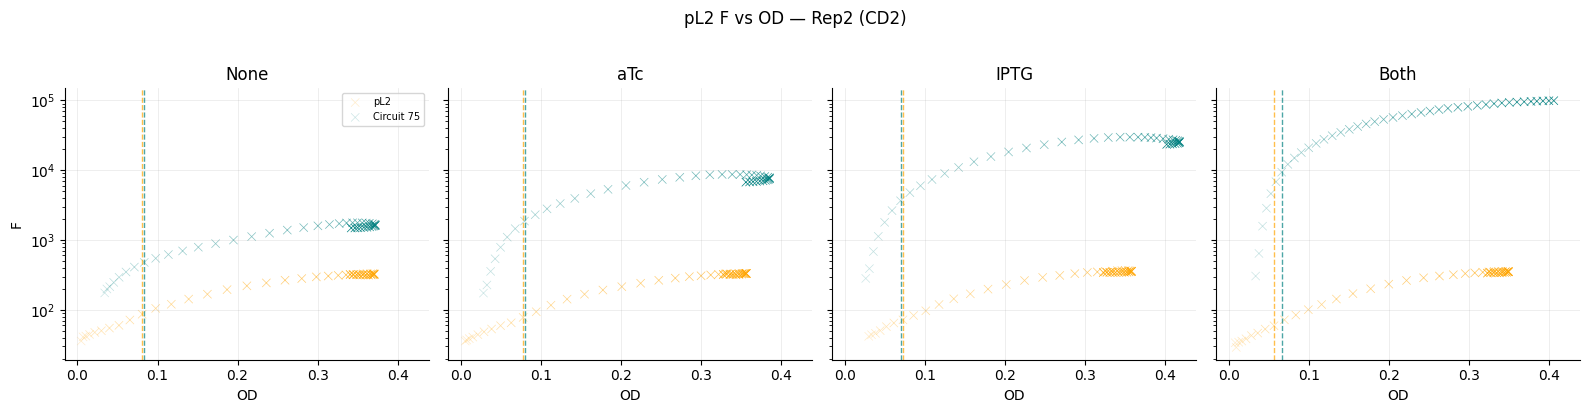

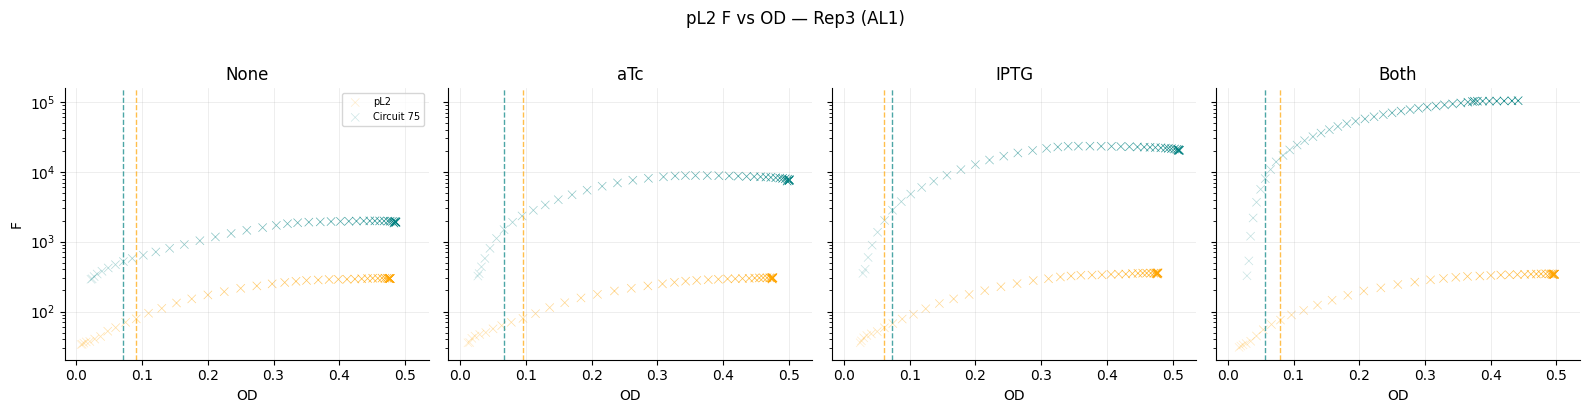

In [12]:
# pL2 & SAMPLE: F vs OD

for rep in REPLICATES:
    tag = rep["tag"]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)

    for well in range(4):
        ax = axes[well]

        n = pl2_biomass[tag][well].shape[-1]
        alphas = np.linspace(0.2, 1.0, n)
        
        # F vs OD
        ax.scatter(pl2_biomass[tag][well],
                pl2_fl_no_bg[tag][well],
                color="orange",
                lw=0.5,
                marker='x',
                alpha=alphas,
                label="pL2")
        ax.axvline(
            pl2_biomass_at_sampled[tag][well], color="orange", ls="--", lw=1, alpha=0.7
        )
        
        n = circuit_biomass[tag][well].shape[-1]
        alphas = np.linspace(0.2, 1.0, n)
        
        ax.scatter(circuit_biomass[tag][well],
                circuit_fl_no_bg[tag][well],
                color="teal",
                lw=0.5,
                marker='x',
                alpha=alphas,
                label=f"Circuit {CIRCUIT}")
        ax.axvline(
            circuit_biomass_at_sampled[tag][well], color="teal", ls="--", lw=1, alpha=0.7
        )
            
            
        ax.set_title(REPLICATES[0]["cond_labels"][well])
        ax.set_xlabel("OD")
        ax.grid(True, alpha=0.3, linewidth=0.5)
        ax.set_yscale("log")
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        if well == 0:
            ax.set_ylabel("F")
            ax.legend(fontsize=7)

    fig.suptitle(f"pL2 F vs OD — {tag} ({rep['label']})", y=1.02)
    plt.tight_layout()
    plt.show()


## Autofluorescence Calibration Curve


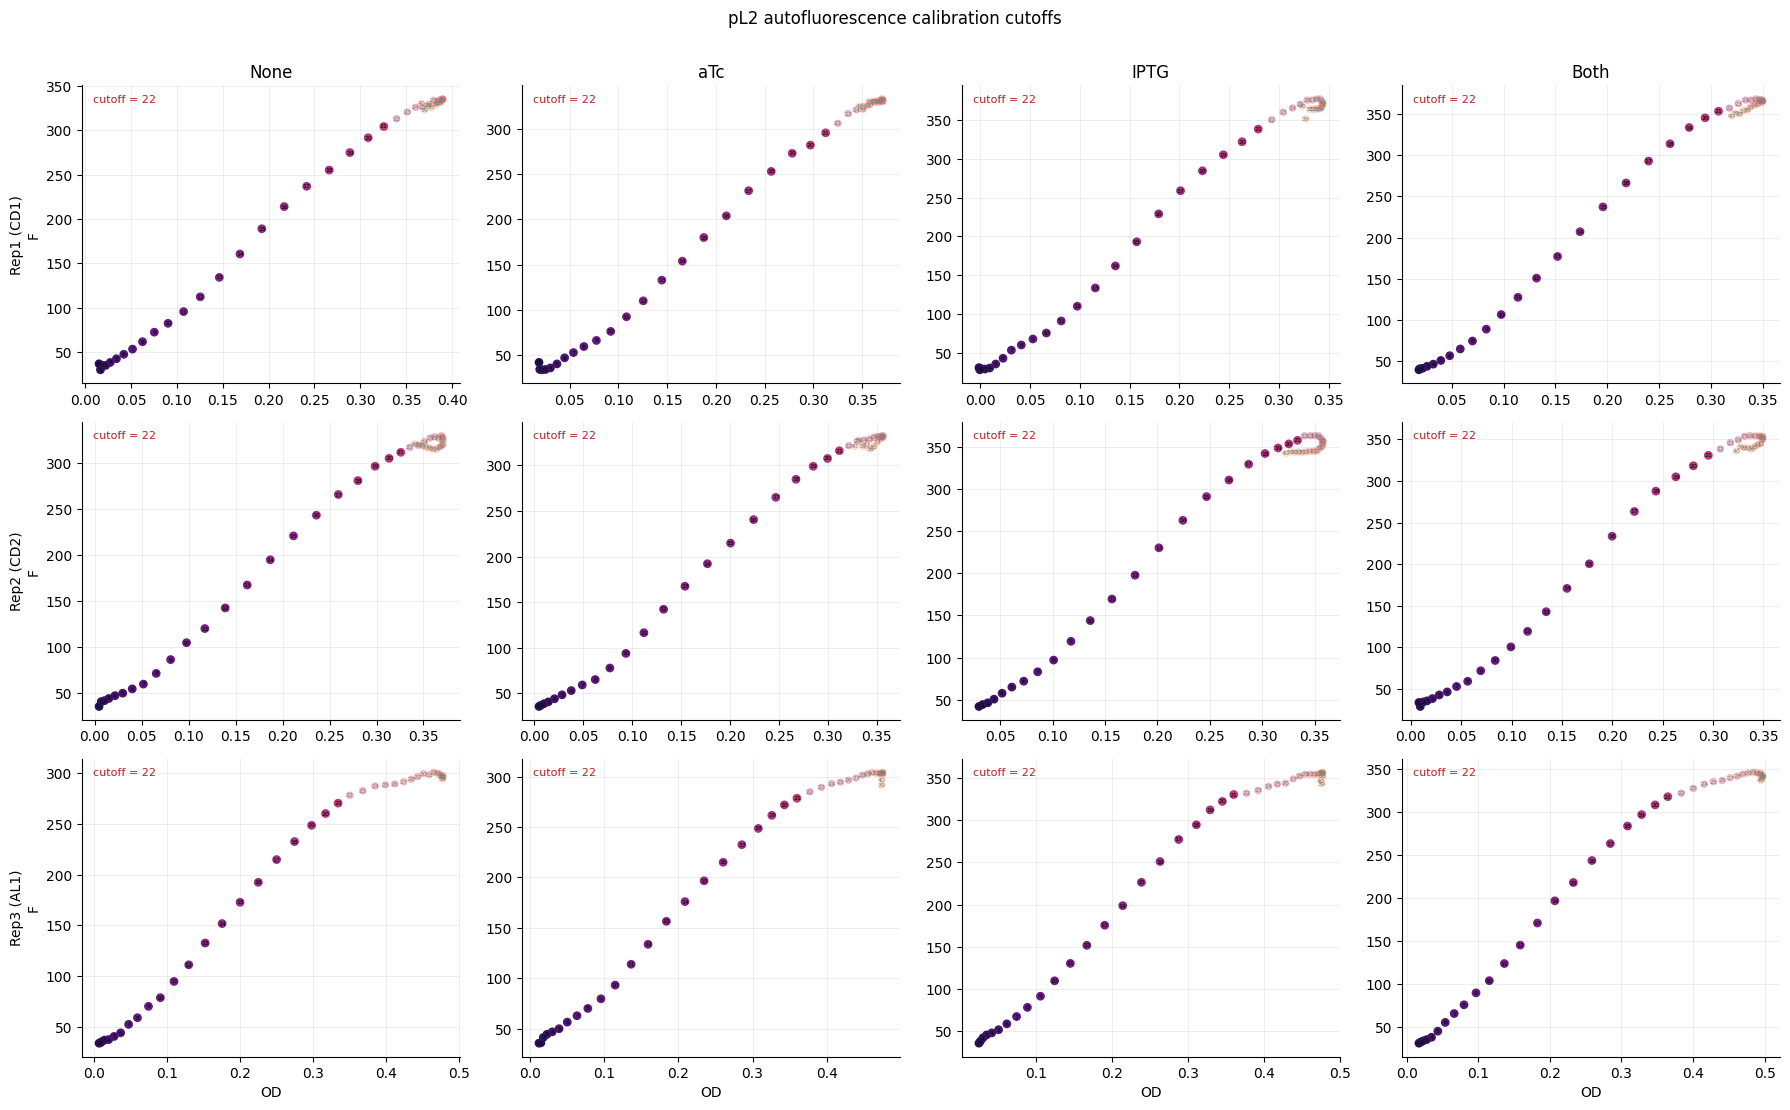

In [ ]:
# pL2 F vs OD, coloured by timepoint
# Faded tail should be where the curve loops back

fig, axes = plt.subplots(len(REPLICATES), 4, figsize=(18, 11), sharex=False)
n_t = len(t_minutes_shared)

for rep_i, rep in enumerate(REPLICATES):
    tag = rep["tag"]
    for well in range(4):
        ax = axes[rep_i, well]
        cutoff = PL2_FIT_CUTOFF[rep["label"]][rep["cond_labels"][well]]
        od_well = pl2_biomass[tag][well]
        fl_well = pl2_fl_no_bg[tag][well]
        index = np.arange(n_t)

        kept = index < cutoff
        ax.scatter(od_well[kept], fl_well[kept], c=index[kept], cmap=INDEX_CMAP,
                   vmin=0, vmax=n_t, s=28, zorder=3)
        ax.scatter(od_well[~kept], fl_well[~kept], c=index[~kept], cmap=INDEX_CMAP,
                   vmin=0, vmax=n_t, s=20, alpha=0.3, zorder=2)
        # Index labels
        for i in range(n_t):
            ax.annotate(str(i), (od_well[i], fl_well[i]), fontsize=4.5,
                        ha="center", va="center",
                        color="black" if kept[i] else "gray")

        ax.grid(True, alpha=0.3, linewidth=0.5)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        if rep_i == 0:
            ax.set_title(rep["cond_labels"][well])
        if rep_i == len(REPLICATES) - 1:
            ax.set_xlabel("OD")
        if well == 0:
            ax.set_ylabel(f"{tag} ({rep['label']})\nF")
        ax.text(0.03, 0.97, f"cutoff = {cutoff}", transform=ax.transAxes,
                ha="left", va="top", fontsize=8, color="firebrick")

fig.suptitle("pL2 autofluorescence calibration cutoffs", y=1.005)
plt.tight_layout()
plt.show()


In [14]:
# Fit calibration curves
autofl_coeffs = {}
autofl_od_range = {}

for rep in REPLICATES:
    tag = rep["tag"]
    autofl_coeffs[tag], autofl_od_range[tag] = {}, {}
    for well in range(4):
        condition = rep["cond_labels"][well]
        # PL2_FIT_CUTOFF drops stationary phase
        cutoff = PL2_FIT_CUTOFF[rep["label"]][condition]
        od_well = pl2_biomass[tag][well][:cutoff]
        fl_well = pl2_fl_no_bg[tag][well][:cutoff]
        autofl_coeffs[tag][well], autofl_od_range[tag][well], keep = (
            transform.fit_autofluorescence(od_well, fl_well, pl2_above_floor[tag][well][:cutoff],
                                           order=AUTOFLUORESCENCE_ORDER))

        low, high = autofl_od_range[tag][well]
        residual = fl_well[keep] - transform.autofluorescence_at(
            autofl_coeffs[tag][well], od_well[keep])
        print(f"{tag} ({rep['label']}) {condition:>4}: {int(keep.sum()):3d} points over "
              f"{low:.4f}-{high:.4f}, RMSE {np.sqrt((residual ** 2).mean()):5.2f}")


def predict_autofluorescence(tag, well, od):
    """pL2 autofluorescence at a given OD, from that condition's own cubic."""
    return transform.autofluorescence_at(autofl_coeffs[tag][well], od)

Rep1 (CD1) None:  22 points over 0.0151-0.3257, RMSE  2.16
Rep1 (CD1)  aTc:  22 points over 0.0185-0.3125, RMSE  2.31
Rep1 (CD1) IPTG:  16 points over 0.0228-0.2793, RMSE  2.37
Rep1 (CD1) Both:  22 points over 0.0182-0.3074, RMSE  0.87
Rep2 (CD2) None:  18 points over 0.0216-0.3258, RMSE  1.52
Rep2 (CD2)  aTc:  18 points over 0.0207-0.3117, RMSE  2.42
Rep2 (CD2) IPTG:  22 points over 0.0295-0.3337, RMSE  1.46
Rep2 (CD2) Both:  19 points over 0.0161-0.2953, RMSE  1.40
Rep3 (AL1) None:  17 points over 0.0278-0.3342, RMSE  0.95
Rep3 (AL1)  aTc:  18 points over 0.0297-0.3600, RMSE  1.87
Rep3 (AL1) IPTG:  22 points over 0.0246-0.3605, RMSE  1.28
Rep3 (AL1) Both:  19 points over 0.0279-0.3647, RMSE  1.35


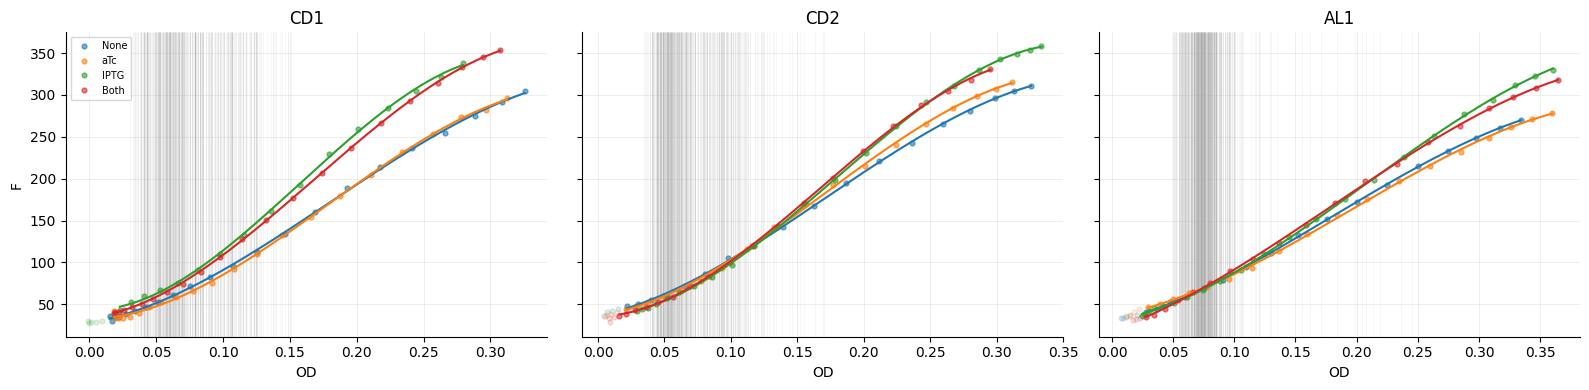

In [ ]:
# Each condition's cubic fit


fig, axes = plt.subplots(1, len(REPLICATES), figsize=FIGSIZE_CALIBRATION, sharey=True)
for rep_i, rep in enumerate(REPLICATES):
    tag = rep["tag"]
    ax = axes[rep_i]
    for well in range(4):
        condition = rep["cond_labels"][well]
        cutoff = PL2_FIT_CUTOFF[rep["label"]][condition]
        od_well = pl2_biomass[tag][well][:cutoff]
        fl_well = pl2_fl_no_bg[tag][well][:cutoff]
        # Below-floor points are excluded from the fit
        in_fit = pl2_above_floor[tag][well][:cutoff]
        ax.plot(od_well[~in_fit], fl_well[~in_fit], "o", color=CONDITION_COLORS[well],
                ms=2.2, alpha=0.15)
        ax.plot(od_well[in_fit], fl_well[in_fit], "o", color=CONDITION_COLORS[well],
                ms=2.2, alpha=0.6, label=condition)
        low, high = autofl_od_range[tag][well]
        grid = np.linspace(low, high, 200)
        ax.plot(grid, predict_autofluorescence(tag, well, grid),
                color=CONDITION_COLORS[well], lw=1.0, zorder=4)

    # Every circuit's sampled OD on this plate
    ax.vlines(circuit_sampled_ods[tag], 0, 1, transform=ax.get_xaxis_transform(),
              color="gray", lw=0.4, alpha=0.12, zorder=1)
    for well in range(4):
        ax.axvline(pRPU_biomass_at_sampled[tag][well], color="gray", lw=0.8, alpha=0.12,
                   zorder=2)

    ax.grid(True, alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.set_xlabel("OD", fontsize=LABEL_FONTSIZE)
    ax.set_title(rep["label"], fontsize=LABEL_FONTSIZE)
    ax.tick_params(which="both", labelsize=TICK_FONTSIZE)
    if rep_i == 0:
        ax.set_ylabel("F", fontsize=LABEL_FONTSIZE)
        ax.legend(fontsize=LEGEND_FONTSIZE, loc="upper left", handlelength=1.2,
                  borderpad=0.4, labelspacing=0.3)

plt.tight_layout()
plt.show()